# Classify recordings with clinical features

In [15]:
import hashlib
from pathlib import Path
from time import perf_counter

import cloudpickle
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.svm import SVC
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from tabm import TabM
from tqdm import tqdm

torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

## Load the data

In [16]:
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
                    if (path / 'data' / 'capslpdb' / 'recordings.csv').is_file())
SPLIT_DIR = PROJECT_ROOT / 'outputs' / 'splits'
MODEL_FILE = PROJECT_ROOT / 'outputs' / 'models' / 'clinical_models.pkl'
SEEDS = (11, 29, 42, 73, 101)
CLASSES = np.array(['healthy', 'other', 'rbd'])

ARCHITECTURE_FEATURES = ['sleep_efficiency', 'waso_min', 'awakenings_per_h', 'stage_shifts_per_h', 'pct_rem', 'sws_first_half']
CAP_FEATURES = ['cap_rate', 'cap_a_index', 'cap_a3_index', 'cap_a1_share']
RSWA_FEATURES = ['rem_atonia_index', 'rem_any3_bg2', 'diff_phasic1_local3', 'rem_tonic_bg2', 'diff_log_rms_p90']
WINDOW_FEATURES = ['sws_delta', 's2_emg_sd', 'rem_theta_alpha']
FEATURES = RSWA_FEATURES + WINDOW_FEATURES + ARCHITECTURE_FEATURES + CAP_FEATURES


splits = {name: pd.read_csv(SPLIT_DIR / f'{name}.csv') for name in ('train', 'validation')}
split_ids = pd.concat([table['record_id'] for table in splits.values()], ignore_index=True)
if not split_ids.is_unique:
    raise ValueError('Training and validation contain duplicate recordings.')

## Define the models

In [17]:
class FixedEpochTabM(ClassifierMixin, BaseEstimator):
    """TabM trained for a fixed number of full-batch epochs on already balanced data."""

    def __init__(self, epochs=40, seed=42, verbose=False):
        self.epochs = epochs
        self.seed = seed
        self.verbose = verbose

    def fit(self, X, y):
        torch.manual_seed(self.seed)
        self.classes_, encoded = np.unique(y, return_inverse=True)
        self.scaler_ = StandardScaler().fit(X)
        x = torch.tensor(self.scaler_.transform(X), dtype=torch.float32)
        self.model_ = TabM.make(n_num_features=x.shape[1], d_out=len(self.classes_),
                                n_blocks=2, d_block=64, dropout=0.1, k=16)
        target = torch.tensor(encoded, dtype=torch.long).repeat_interleave(self.model_.k)
        optimizer = torch.optim.AdamW(self.model_.parameters(), lr=0.001, weight_decay=0.0001)
        self.model_.train()
        self.loss_curve_ = []
        for epoch in range(self.epochs):
            optimizer.zero_grad()
            loss = F.cross_entropy(self.model_(x).reshape(-1, len(self.classes_)), target)
            loss.backward()
            optimizer.step()
            self.loss_curve_.append(float(loss.detach()))
            if self.verbose and (epoch == 0 or (epoch + 1) % 10 == 0):
                print(f'Epoch {epoch + 1:02d}/{self.epochs} | training loss: {loss.item():.4f}')
        self.model_.eval()
        return self

    def predict_proba(self, X):
        with torch.no_grad():
            x = torch.tensor(self.scaler_.transform(X), dtype=torch.float32)
            return self.model_(x).softmax(dim=-1).mean(dim=1).numpy()

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


def oversample(y, rng):
    groups = [np.flatnonzero(y == label) for label in np.unique(y)]
    largest = max(len(group) for group in groups)
    selected = [rng.choice(group, size=largest, replace=len(group) < largest) for group in groups]
    return rng.permutation(np.concatenate(selected))

def extra_trees(seed):
    return ExtraTreesClassifier(n_estimators=1000, min_samples_leaf=2, max_features=0.5,
                                class_weight='balanced', random_state=seed, n_jobs=-1)

def make_models(seed, verbose=False):
    logistic = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight='balanced', max_iter=5000))
    ensemble = VotingClassifier([('logistic_regression', logistic), ('extra_trees', extra_trees(seed))], voting='soft')
    estimators = {
        'Majority baseline': DummyClassifier(strategy='most_frequent'),
        'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000)),
        'RBF SVM': make_pipeline(RobustScaler(), SVC(C=1, kernel='rbf', class_weight='balanced')),
        'Random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=seed, n_jobs=1),
        'XGBoost': XGBClassifier(n_estimators=40, max_depth=3, learning_rate=0.05, reg_lambda=3,
                                 objective='multi:softprob', num_class=len(CLASSES), random_state=seed, n_jobs=1),
        'CatBoost': CatBoostClassifier(iterations=60, depth=3, learning_rate=0.05, loss_function='MultiClass',
                                       random_seed=seed, thread_count=1, verbose=False, allow_writing_files=False),
        'TabM': FixedEpochTabM(seed=seed, verbose=verbose),
        'Extra trees': extra_trees(seed),
        'Soft-voting ensemble': ensemble,
    }
    return {name: make_pipeline(SimpleImputer(strategy='median', keep_empty_features=True), model)
            for name, model in estimators.items()}

OVERSAMPLED_MODELS = {'Logistic regression', 'Random forest', 'XGBoost', 'CatBoost', 'TabM'}

def scores(y, prediction):
    recalls = recall_score(y, prediction, labels=np.arange(len(CLASSES)), average=None, zero_division=0)
    return {'balanced_accuracy': balanced_accuracy_score(y, prediction),
            'macro_f1': f1_score(y, prediction, labels=np.arange(len(CLASSES)), average='macro', zero_division=0),
            **{f'{name}_recall': value for name, value in zip(CLASSES, recalls)}}

## Cross-validation

Compare the models on the training split using five seeds and three folds.

In [18]:
train = splits['train']
X_train = train[FEATURES]
y_train = pd.Categorical(train['class_name'], categories=CLASSES).codes
predictions = []
for seed in tqdm(SEEDS, desc='Cross-validation', unit='seed'):
    splitter = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
    for fold, (fit, held) in enumerate(splitter.split(X_train, y_train)):
        model_seed = seed + fold
        balanced = fit[oversample(y_train[fit], np.random.default_rng(model_seed))]
        for name, model in make_models(model_seed).items():
            indices = balanced if name in OVERSAMPLED_MODELS else fit
            model.fit(X_train.iloc[indices], y_train[indices])
            prediction = np.asarray(model.predict(X_train.iloc[held])).astype(int).ravel()
            predictions.extend({'seed': seed, 'model': name, 'record_id': train.iloc[index]['record_id'],
                                'true': y_train[index], 'predicted': int(value)}
                               for index, value in zip(held, prediction))

out_of_fold = pd.DataFrame(predictions)
if not out_of_fold.groupby(['seed', 'model', 'record_id']).size().eq(1).all():
    raise ValueError('Each recording must have one prediction per model and seed.')
per_seed = pd.DataFrame([{'seed': seed, 'model': model, **scores(group['true'], group['predicted'])}
                         for (seed, model), group in out_of_fold.groupby(['seed', 'model'])])
metrics = ['balanced_accuracy', 'macro_f1', 'healthy_recall', 'other_recall', 'rbd_recall']
grouped = per_seed.groupby('model')[metrics]
mean = grouped.mean().sort_values('balanced_accuracy', ascending=False)
spread = grouped.std().loc[mean.index]
summary = pd.DataFrame({metric: [f'{a:.3f} \u00b1 {b:.3f}' for a, b in zip(mean[metric], spread[metric])]
                        for metric in metrics}, index=mean.index)
display(summary)

Cross-validation: 100%|██████████| 5/5 [00:28<00:00,  5.72s/seed]


,balanced_accuracy,macro_f1,healthy_recall,other_recall,rbd_recall
model,,,,,
TabM,0.722 ± 0.057,0.660 ± 0.055,0.733 ± 0.061,0.663 ± 0.044,0.769 ± 0.109
RBF SVM,0.687 ± 0.068,0.637 ± 0.062,0.711 ± 0.127,0.659 ± 0.075,0.692 ± 0.077
CatBoost,0.653 ± 0.081,0.651 ± 0.090,0.533 ± 0.145,0.780 ± 0.083,0.646 ± 0.117
Soft-voting ensemble,0.643 ± 0.044,0.639 ± 0.045,0.467 ± 0.093,0.800 ± 0.020,0.662 ± 0.088
Logistic regression,0.614 ± 0.044,0.594 ± 0.036,0.556 ± 0.157,0.717 ± 0.028,0.569 ± 0.088
Random forest,0.566 ± 0.073,0.583 ± 0.080,0.311 ± 0.093,0.834 ± 0.068,0.554 ± 0.126
Extra trees,0.557 ± 0.074,0.574 ± 0.085,0.200 ± 0.093,0.888 ± 0.041,0.585 ± 0.129
XGBoost,0.549 ± 0.065,0.565 ± 0.081,0.400 ± 0.099,0.800 ± 0.087,0.446 ± 0.034
Majority baseline,0.333 ± 0.000,0.263 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000


## Training

Fit the models on the training and validation recordings and save them for later use.

In [19]:
development = pd.concat([splits['train'], splits['validation']], ignore_index=True)
X_development = development[FEATURES]
y_development = pd.Categorical(development['class_name'], categories=CLASSES).codes
balanced = oversample(y_development, np.random.default_rng(42))
models = make_models(42)
training_rows = []
steps = {'Majority baseline': 'Baseline', 'Logistic regression': 'Single fit', 'RBF SVM': 'Single fit',
         'Random forest': '300 trees', 'XGBoost': '40 boosting rounds', 'CatBoost': '60 boosting rounds',
         'TabM': '40 epochs', 'Extra trees': '1000 trees', 'Soft-voting ensemble': 'Two models'}
progress = tqdm(models.items(), desc='Training', unit='model')
for name, model in progress:
    progress.set_postfix_str(name)
    indices = balanced if name in OVERSAMPLED_MODELS else np.arange(len(development))
    started = perf_counter()
    model.fit(X_development.iloc[indices], y_development[indices])
    training_rows.append({'model': name, 'fit_rows': len(indices),
                          'training_mode': steps[name], 'seconds': perf_counter() - started})

def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

MODEL_FILE.parent.mkdir(parents=True, exist_ok=True)
bundle = {'models': models, 'features': FEATURES, 'classes': CLASSES.tolist(),
          'development_ids': development['record_id'].tolist(),
          'hashes': {name: sha256(SPLIT_DIR / f'{name}.csv') for name in ('train', 'validation')}}
with MODEL_FILE.open('wb') as file:
    cloudpickle.dump(bundle, file)
print('\n' + '-' * 40)
print(f'Training data: {len(development)} unique recordings')
print(f'Balanced training: {len(balanced)} rows including repeats\n')
training_summary = pd.DataFrame(training_rows).set_index('model').round({'seconds': 2})
display(training_summary.rename(columns={'fit_rows': 'Fit rows', 'training_mode': 'Training', 'seconds': 'Time (s)'}))
losses = models['TabM'].named_steps['fixedepochtabm'].loss_curve_
epochs = [1, 10, 20, 30, 40]
print('\n' + '-' * 40)
print('TabM training loss (not validation loss):')
display(pd.DataFrame({'epoch': epochs, 'training_loss': [losses[epoch - 1] for epoch in epochs]}).set_index('epoch').round(4))
print('\n' + '-' * 40)
print(f'Saved models to {MODEL_FILE.relative_to(PROJECT_ROOT)}')

Training: 100%|██████████| 9/9 [00:01<00:00,  5.07model/s, Soft-voting ensemble]


----------------------------------------
Training data: 74 unique recordings
Balanced training: 144 rows including repeats



,Fit rows,Training,Time (s)
model,,,
Majority baseline,74,Baseline,0.00
Logistic regression,144,Single fit,0.01
RBF SVM,74,Single fit,0.00
Random forest,144,300 trees,0.18
XGBoost,144,40 boosting rounds,0.05
CatBoost,144,60 boosting rounds,0.05
TabM,144,40 epochs,0.16
Extra trees,74,1000 trees,0.66
Soft-voting ensemble,74,Two models,0.65



----------------------------------------
TabM training loss (not validation loss):


,training_loss
epoch,
1,1.1046
10,1.0498
20,0.9827
30,0.8859
40,0.7722



----------------------------------------
Saved models to outputs\models\clinical_models.pkl


## Test

Evaluate the saved models on the test split.

In [20]:
import hashlib
from pathlib import Path

import cloudpickle
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, recall_score

PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
                    if (path / 'data' / 'capslpdb' / 'recordings.csv').is_file())
SPLIT_DIR = PROJECT_ROOT / 'outputs' / 'splits'
MODEL_FILE = PROJECT_ROOT / 'outputs' / 'models' / 'clinical_models.pkl'
with MODEL_FILE.open('rb') as file:
    saved = cloudpickle.load(file)

for name, expected in saved['hashes'].items():
    if hashlib.sha256((SPLIT_DIR / f'{name}.csv').read_bytes()).hexdigest() != expected:
        raise ValueError(f'The {name} split changed. Train the models again.')
test = pd.read_csv(SPLIT_DIR / 'test.csv')
if set(test['record_id']) & set(saved['development_ids']):
    raise ValueError('The test split overlaps with the training or validation split.')
classes = saved['classes']
y_test = pd.Categorical(test['class_name'], categories=classes).codes
results = []
test_predictions = {}
for name, model in saved['models'].items():
    prediction = np.asarray(model.predict(test[saved['features']])).astype(int).ravel()
    test_predictions[name] = prediction
    recalls = recall_score(y_test, prediction, labels=np.arange(len(classes)), average=None, zero_division=0)
    results.append({'model': name, 'balanced_accuracy': balanced_accuracy_score(y_test, prediction),
                    'macro_f1': f1_score(y_test, prediction, labels=np.arange(len(classes)), average='macro', zero_division=0),
                    'accuracy': accuracy_score(y_test, prediction),
                    **{f'{label}_recall': value for label, value in zip(classes, recalls)}})
display(pd.DataFrame(results).set_index('model').round(3))

,balanced_accuracy,macro_f1,accuracy,healthy_recall,other_recall,rbd_recall
model,,,,,,
Majority baseline,0.333,0.264,0.656,0.00,1.000,0.000
Logistic regression,0.758,0.688,0.719,0.75,0.667,0.857
RBF SVM,0.806,0.718,0.750,0.75,0.667,1.000
Random forest,0.837,0.832,0.875,0.75,0.905,0.857
XGBoost,0.742,0.705,0.750,0.75,0.762,0.714
CatBoost,0.774,0.716,0.750,0.75,0.714,0.857
TabM,0.758,0.647,0.656,0.75,0.524,1.000
Extra trees,0.821,0.801,0.844,0.75,0.857,0.857
Soft-voting ensemble,0.853,0.806,0.844,0.75,0.810,1.000


## Test confusion matrices

Run the test cell first to show the predictions for each model.

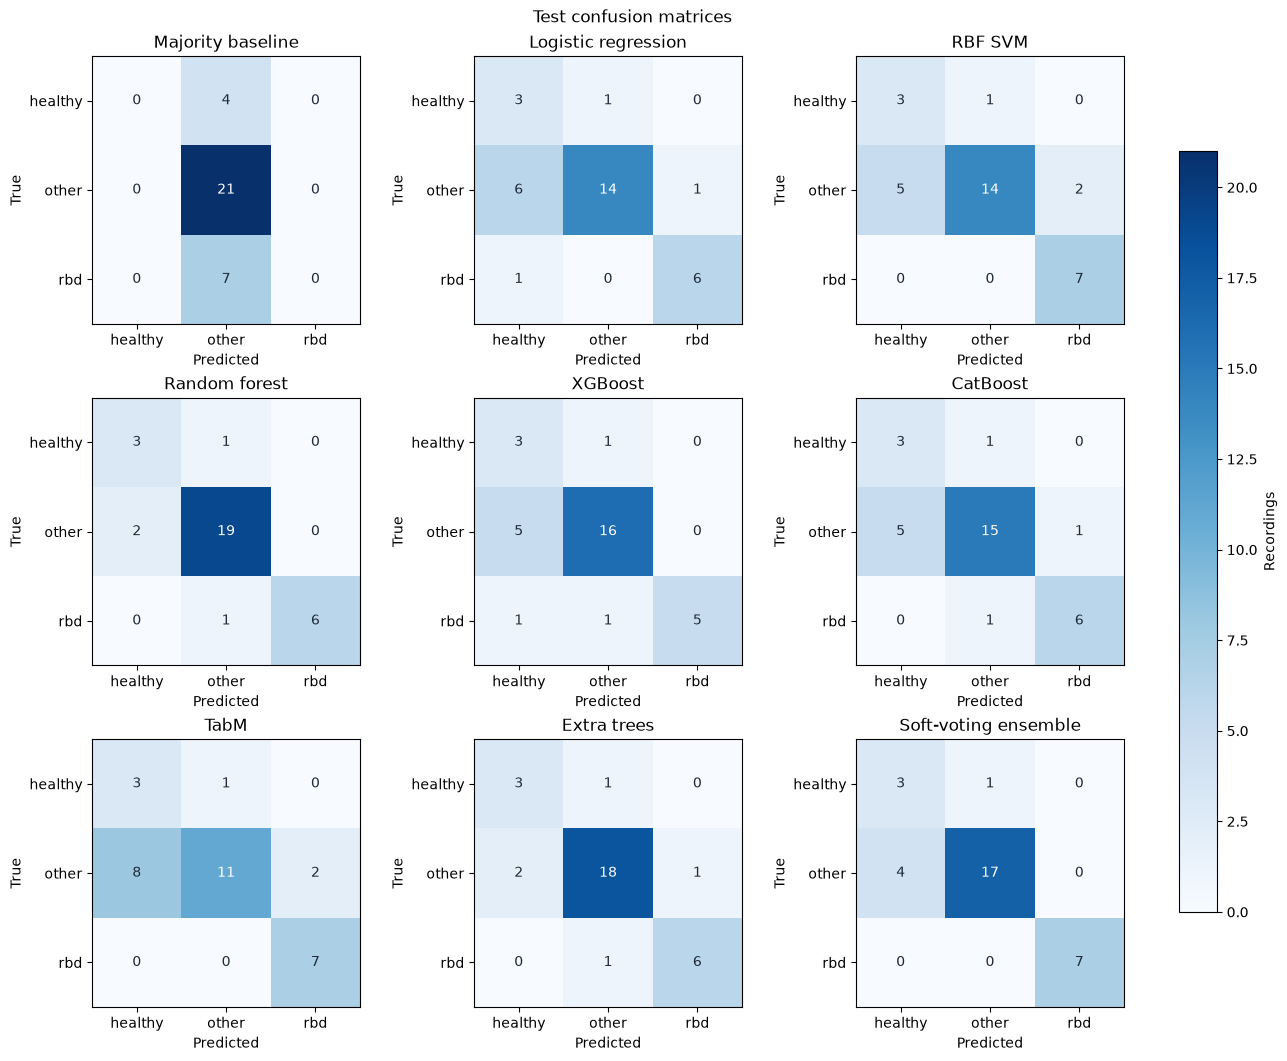

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

columns = 3
rows = (len(test_predictions) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(13, rows * 3.5), squeeze=False, layout='constrained')
limit = np.bincount(y_test, minlength=len(classes)).max()
for ax, (name, prediction) in zip(axes.flat, test_predictions.items()):
    matrix = confusion_matrix(y_test, prediction, labels=np.arange(len(classes)))
    image = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=limit)
    for row in range(len(classes)):
        for column in range(len(classes)):
            value = matrix[row, column]
            ax.text(column, row, value, ha='center', va='center',
                    color='white' if value > limit / 2 else '#1f2937')
    ax.set(title=name, xticks=range(len(classes)), yticks=range(len(classes)),
           xticklabels=classes, yticklabels=classes, xlabel='Predicted', ylabel='True')

for ax in list(axes.flat)[len(test_predictions):]:
    fig.delaxes(ax)
fig.colorbar(image, ax=fig.axes, label='Recordings', shrink=0.8)
fig.suptitle('Test confusion matrices')
plt.show()